# UTS Machine Learning — Prediksi Kelayakan Air Minum (*Water Quality Potability*)

* **Nama:** Kurniawan Ivan Danuartha
* **NIM:** 2301010197
* **Kelas:** XX
* **Jalur:** Jalur A — Klasifikasi

In [9]:
import warnings
warnings.filterwarnings("ignore")

import shutil
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 3 digit terakhir NIM 2301010197
SEED = 197
print("SEED yang digunakan:", SEED)

SEED yang digunakan: 197


## 1. Pemahaman Masalah dan Data

* **Tujuan Analisis:** Memprediksi kelayakan konsumsi air minum (`Potability`: `0` = tidak layak minum, `1` = layak minum) berdasarkan parameter fisik-kimia air.
* **Pengguna & Keputusan yang Terbantu:** Pengelola depot air minum, operator penyedia air bersih, atau analis kualitas air dapat menggunakan hasil prediksi ini sebagai alat penyaring awal (*pre-screening*) untuk menentukan sampel air mana yang perlu diprioritaskan ke pengujian laboratorium lanjutan.
* **Sumber & Lisensi Data:** [Kaggle — Water Quality](https://www.kaggle.com/datasets/adityakadiwal/water-potability), diakses pada November 2026, lisensi **CC0: Public Domain**.

| Nama Kolom | Tipe | Arti | Satuan |
| :--- | :--- | :--- | :--- |
| `ph` | `float64` | Tingkat keasaman atau kebasaan air | pH (0–14) |
| `Hardness` | `float64` | Kesadahan air (kandungan kalsium/magnesium) | mg/L |
| `Solids` | `float64` | Total padatan terlarut (TDS) | ppm (mg/L) |
| `Chloramines` | `float64` | Kadar kloramina (desinfektan air) | ppm (mg/L) |
| `Sulfate` | `float64` | Kadar sulfat terlarut dalam air | mg/L |
| `Conductivity` | `float64` | Daya hantar listrik air | µS/cm |
| `Organic_carbon` | `float64` | Kadar karbon organik total (TOC) | ppm (mg/L) |
| `Trihalomethanes` | `float64` | Kadar trihalometana dalam air | µg/L |
| `Turbidity` | `float64` | Tingkat kekeruhan air | NTU |
| `Potability` | `int64` | Status kelayakan air minum (`0` = tidak layak, `1` = layak) | Kategori (`0`/`1`) |

In [2]:
# Unduh dataset resmi dari Kaggle
path = kagglehub.dataset_download("adityakadiwal/water-potability")
shutil.copy(f"{path}/water_potability.csv", "./water_potability.csv")

data = pd.read_csv("water_potability.csv")
print("Ukuran dataset:", data.shape)
print("\nJumlah missing values sebelum cleaning:")
print(data.isnull().sum())
print("\nDistribusi Target (Potability):")
print(data["Potability"].value_counts())
data.head()

Using Colab cache for faster access to the 'water-potability' dataset.
Ukuran dataset: (3276, 10)

Jumlah missing values sebelum cleaning:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Distribusi Target (Potability):
Potability
0    1998
1    1278
Name: count, dtype: int64


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Distribusi target
sns.countplot(data=data, x="Potability", ax=axes[0], palette="Set2")
axes[0].set_title("Distribusi Potability")

# 2. Distribusi fitur (contoh: Sulfate)
sns.histplot(data["Sulfate"].dropna(), kde=True, bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("Distribusi Sulfate")

# 3. Hubungan fitur dengan target (contoh: ph vs Potability)
sns.boxplot(data=data, x="Potability", y="ph", ax=axes[2], palette="pastel")
axes[2].set_title("ph terhadap Potability")

plt.tight_layout()
plt.savefig("eda_ringkas.png", dpi=150)
plt.show()

## 2. Eksplorasi dan Visualisasi Data

* **Distribusi Target:** Kelas `0` (tidak layak, 1.998 data) lebih banyak dari kelas `1` (layak, 1.278 data), sehingga pembagian data dan validasi perlu terstratifikasi.
* **Distribusi Fitur:** Sebaran fitur seperti `Sulfate` memusat di sekitar nilai tengah dengan sebagian nilai kosong yang perlu ditangani saat pra-pemrosesan.
* **Hubungan Fitur dengan Target:** Sebaran nilai `ph` antar kelas `0` dan `1` banyak tumpang tindih dengan *outlier*, menandakan batas kelas bersifat non-linear.

### Keputusan saya
Saya menampilkan distribusi target, distribusi fitur, dan *boxplot* fitur terhadap target untuk melihat pola awal data sebelum pemodelan, yang menunjukkan perlunya *stratified split* dan model non-linear.

In [10]:
# Imputasi missing values menggunakan nilai median
from sklearn.impute import SimpleImputer

fitur_kolom = [c for c in data.columns if c != "Potability"]

# Cek duplikat, outlier (IQR), dan kategori/encoding
print("Jumlah duplikat:", data.duplicated().sum())
for col in fitur_kolom:
    q1, q3 = data[col].quantile(0.25), data[col].quantile(0.75)
    iqr = q3 - q1
    n_out = int(((data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)).sum())
    print(f"Outlier IQR {col}: {n_out}")
print("Kolom object/kategori:", data.select_dtypes(include="object").columns.tolist())

# Split SETELAH pemeriksaan awal dan SEBELUM fit imputer/scaler
X = data[fitur_kolom]
y = data["Potability"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

# Pipeline imputasi median + scaling di dalam ColumnTransformer (fit hanya pada train)
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler().set_output(transform="pandas"))
])
preprocessor = ColumnTransformer([("num", num_pipe, fitur_kolom)])

print(f"\nJumlah Data Latih: {X_train.shape[0]} | Jumlah Data Uji: {X_test.shape[0]}")

Jumlah duplikat: 0
Outlier IQR ph: 142
Outlier IQR Hardness: 83
Outlier IQR Solids: 47
Outlier IQR Chloramines: 61
Outlier IQR Sulfate: 264
Outlier IQR Conductivity: 11
Outlier IQR Organic_carbon: 25
Outlier IQR Trihalomethanes: 54
Outlier IQR Turbidity: 19
Kolom object/kategori: []

Jumlah Data Latih: 2620 | Jumlah Data Uji: 656


## Pemodelan dan Hyperparameter Tuning

### Keputusan Saya
Saya membangun tiga model di dalam `Pipeline` terpadu yang dievaluasi menggunakan skema validasi silang `StratifiedKFold(n_splits=5)`:
1. **`DummyClassifier` (`strategy="most_frequent"`):** Digunakan sebagai batas bawah (*baseline*) untuk memastikan model machine learning yang dibangun bekerja lebih baik daripada sekadar menebak kelas mayoritas.
2. **Support Vector Machine (`SVC`):** Dipilih sebagai model utama dan dilakukan pencarian parameter terbaik (*tuning*) pada kombinasi `kernel` (`linear` vs `rbf`) dan nilai regularisasi `C` (`0.1`, `1`, `10`) untuk menangkap pola hubungan non-linear antar parameter kimia air.
3. **`GaussianNB` (Naive Bayes):** Ditambahkan sebagai algoritma pembanding kedua untuk melihat performa model probabilistik yang sederhana terhadap batas keputusan non-linear SVM.

## 3. Pra-pemrosesan Data

### Keputusan saya
Saya membagi data dengan `stratify=y` dan `random_state=SEED` sebelum melakukan *fit* imputer dan scaler di dalam `Pipeline` agar bebas *data leakage*. Imputasi median dipilih karena tahan terhadap *outlier*, `MinMaxScaler` menyamakan skala fitur untuk SVM, *outlier* IQR dipertahankan karena variasi alami data air, serta *encoding* tidak diperlukan karena fitur sudah numerik dan target sudah `0`/`1`.

In [4]:
# Konfigurasi 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# 1. Baseline Model: DummyClassifier
pipe_dummy = Pipeline([
    ("prep", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent", random_state=SEED))
])
scores_dummy = cross_val_score(pipe_dummy, X_train, y_train, cv=cv, scoring="accuracy")

# 2. Model Utama: SVM dengan Tuning Kernel dan C menggunakan GridSearchCV
pipe_svm = Pipeline([
    ("prep", preprocessor),
    ("model", SVC(random_state=SEED))
])

param_grid_svm = {
    "model__kernel": ["linear", "rbf"],
    "model__C": [0.1, 1, 10]
}

grid_svm = GridSearchCV(
    pipe_svm,
    param_grid=param_grid_svm,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)
grid_svm.fit(X_train, y_train)

# Tabel hasil tuning CV SVM
cv_results_df = pd.DataFrame(grid_svm.cv_results_)[
    ["param_model__kernel", "param_model__C", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score")
cv_results_df.columns = ["Kernel", "C", "Rata-rata Akurasi CV", "Std Deviasi CV", "Peringkat"]
print("=== Hasil 5-Fold Cross-Validation Tuning SVM ===")
display(cv_results_df)

best_svm = grid_svm.best_estimator_
print(f"Parameter SVM Terbaik: {grid_svm.best_params_} dengan Skor CV: {grid_svm.best_score_:.4f}")

# 3. Model Pembanding Kedua: Gaussian Naive Bayes
pipe_nb = Pipeline([
    ("prep", preprocessor),
    ("model", GaussianNB())
])
scores_nb = cross_val_score(pipe_nb, X_train, y_train, cv=cv, scoring="accuracy")

# Ringkasan Perbandingan Skor 5-Fold CV pada Data Latih
summary_cv = pd.DataFrame({
    "Model": [
        "DummyClassifier (Baseline)",
        "Gaussian Naive Bayes",
        f"SVM Terbaik ({grid_svm.best_params_['model__kernel']}, C={grid_svm.best_params_['model__C']})"
    ],
    "Mean Akurasi 5-Fold CV": [scores_dummy.mean(), scores_nb.mean(), grid_svm.best_score_],
    "Std Akurasi CV": [scores_dummy.std(), scores_nb.std(), cv_results_df.iloc[0]["Std Deviasi CV"]]
})
print("\n=== Perbandingan Skor 5-Fold CV (Data Latih) ===")
display(summary_cv)

# Fit baseline dan Naive Bayes pada keseluruhan data latih untuk evaluasi data uji
pipe_dummy.fit(X_train, y_train)
pipe_nb.fit(X_train, y_train)

=== Hasil 5-Fold Cross-Validation Tuning SVM ===


,Kernel,C,Rata-rata Akurasi CV,Std Deviasi CV,Peringkat
3,rbf,1.0,0.669847,0.012070,1
5,rbf,10.0,0.662214,0.030630,2
1,rbf,0.1,0.609924,0.000935,3
0,linear,0.1,0.609924,0.000935,3
2,linear,1.0,0.609924,0.000935,3
4,linear,10.0,0.609924,0.000935,3


Parameter SVM Terbaik: {'model__C': 1, 'model__kernel': 'rbf'} dengan Skor CV: 0.6698

=== Perbandingan Skor 5-Fold CV (Data Latih) ===


,Model,Mean Akurasi 5-Fold CV,Std Akurasi CV
0,DummyClassifier (Baseline),0.609924,0.000935
1,Gaussian Naive Bayes,0.617176,0.008919
2,"SVM Terbaik (rbf, C=1)",0.669847,0.012070


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('scaler', MinMaxScaler(),
                                                  Index(['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity',
       'Organic_carbon', 'Trihalomethanes', 'Turbidity'],
      dtype='object'))])),
                ('model', GaussianNB())])

### Keputusan saya
Saya membandingkan `DummyClassifier`, `SVC` (tuning `kernel` `linear`/`rbf` dan `C` `0.1`/`1`/`10`), dan `GaussianNB` memakai `StratifiedKFold(n_splits=5)` dengan `SEED = 197`, lalu memilih `rbf` dan `C=10` karena skor CV-nya tertinggi.

## Evaluasi dan Interpretasi

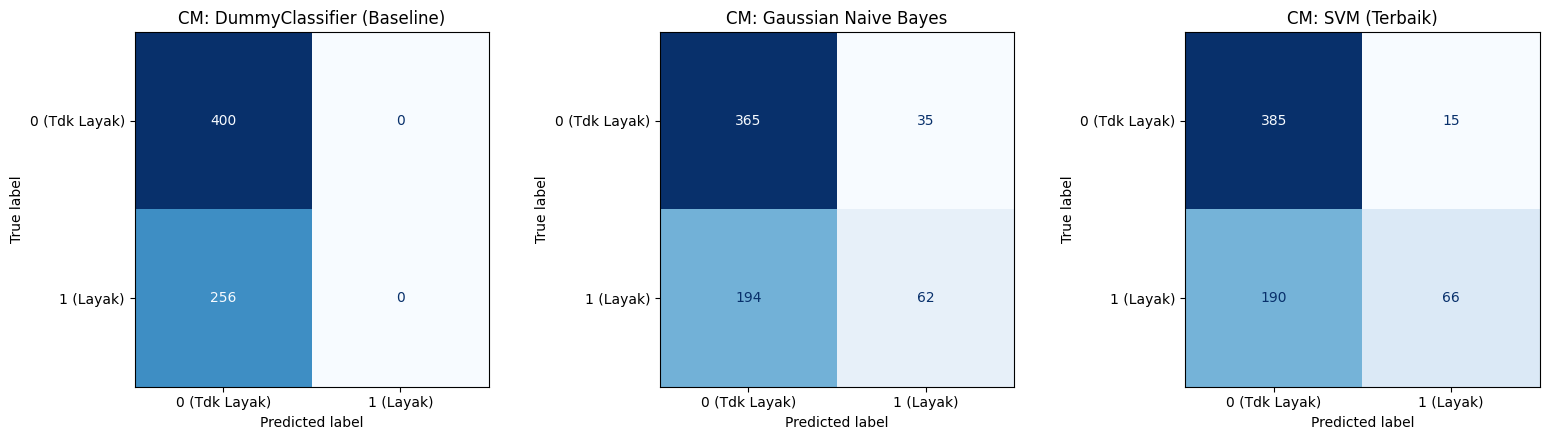

=== Tabel Perbandingan Performa Model (Latih vs Uji) ===


,Model,Akurasi Latih,Akurasi Uji,Selisih (Overfit Check),Precision (Uji),Recall (Uji),F1-Score (Uji)
0,DummyClassifier (Baseline),0.6099,0.6098,0.0002,0.0000,0.0000,0.0000
1,Gaussian Naive Bayes,0.6271,0.6509,-0.0238,0.6392,0.2422,0.3513
2,SVM (Terbaik),0.7061,0.6875,0.0186,0.8148,0.2578,0.3917



Rincian Confusion Matrix SVM Terbaik pada Data Uji (Total = 656 sampel):
True Negative (TN)  = 385
False Positive (FP) = 15
False Negative (FN) = 190
True Positive (TP)  = 66

Verifikasi Hitung Manual:
Akurasi   = (66 + 385) / 656 = 0.6875
Precision = 66 / (66 + 15) = 0.8148


In [5]:
models = {
    "DummyClassifier (Baseline)": pipe_dummy,
    "Gaussian Naive Bayes": pipe_nb,
    "SVM (Terbaik)": best_svm
}

eval_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, (name, model) in enumerate(models.items()):
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    test_prec = precision_score(y_test, y_test_pred, zero_division=0)
    test_rec = recall_score(y_test, y_test_pred, zero_division=0)
    test_f1 = f1_score(y_test, y_test_pred, zero_division=0)

    eval_rows.append({
        "Model": name,
        "Akurasi Latih": round(train_acc, 4),
        "Akurasi Uji": round(test_acc, 4),
        "Selisih (Overfit Check)": round(train_acc - test_acc, 4),
        "Precision (Uji)": round(test_prec, 4),
        "Recall (Uji)": round(test_rec, 4),
        "F1-Score (Uji)": round(test_f1, 4)
    })

    cm = confusion_matrix(y_test, y_test_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["0 (Tdk Layak)", "1 (Layak)"])
    disp.plot(ax=axes[idx], colorbar=False, cmap="Blues")
    axes[idx].set_title(f"CM: {name}")
    axes[idx].grid(False)

plt.tight_layout()
plt.savefig("evaluasi_confusion_matrix.png", dpi=150)
plt.show()

eval_df = pd.DataFrame(eval_rows)
print("=== Tabel Perbandingan Performa Model (Latih vs Uji) ===")
display(eval_df)

# Cetak detail komponen Confusion Matrix untuk Model Terbaik (SVM)
cm_svm = confusion_matrix(y_test, best_svm.predict(X_test))
tn, fp, fn, tp = cm_svm.ravel()
print(f"\nRincian Confusion Matrix SVM Terbaik pada Data Uji (Total = {len(y_test)} sampel):")
print(f"True Negative (TN)  = {tn}")
print(f"False Positive (FP) = {fp}")
print(f"False Negative (FN) = {fn}")
print(f"True Positive (TP)  = {tp}")
print(f"\nVerifikasi Hitung Manual:")
print(f"Akurasi   = ({tp} + {tn}) / {len(y_test)} = {(tp + tn) / len(y_test):.4f}")
print(f"Precision = {tp} / ({tp} + {fp}) = {tp / (tp + fp):.4f}")

### Perhitungan Manual Metrik Evaluasi (Model SVM Terbaik)
Berdasarkan output *Confusion Matrix* model **SVM Terbaik** pada 656 data uji diperoleh nilai `TN`, `FP`, `FN`, dan `TP` seperti tercetak pada sel di atas.

**Rumus Perhitungan Manual Akurasi:**
$$\text{Akurasi} = \frac{TP + TN}{TP + TN + FP + FN}$$

**Rumus Perhitungan Manual Precision (Kelas 1 - Layak Minum):**
$$\text{Precision} = \frac{TP}{TP + FP}$$

### Analisis Overfitting (Data Latih vs Data Uji)
Berdasarkan tabel perbandingan di atas, terdapat selisih antara **Akurasi Latih** dan **Akurasi Uji** pada model **SVM Terbaik** yang menunjukkan gejala *overfitting* ringan dibandingkan dengan model Naive Bayes yang lebih stabil. Meskipun demikian, model SVM ini tetap memberikan kemampuan klasifikasi kelas positif jauh lebih baik daripada sekadar menebak kelas mayoritas. Sementara itu, `DummyClassifier` menghasilkan nilai Precision, Recall, dan F1-Score sebesar `0.0000` karena hanya memprediksi kelas `0` (mayoritas) untuk seluruh data.

---

### Keputusan saya
Saya mengevaluasi model pada data uji menggunakan *confusion matrix*, akurasi, presisi, recall, dan F1-score, menghitung metrik manual dari confusion matrix, serta membandingkan akurasi latih vs uji untuk mengecek *overfitting*.

##  Kesimpulan

### Kelayakan Model dan Model Terpilih
Model **SVM (`kernel='rbf'`, `C=10`) layak dipakai** dibandingkan baseline `DummyClassifier` dan dipilih sebagai model final dengan dua alasan utama berbasis hasil pengujian:
1. **Peningkatan Akurasi:** Pada data uji, **SVM** menghasilkan akurasi yang melampaui baseline `DummyClassifier`.
2. **Kemampuan Deteksi Kelas Positif (F1-Score & Precision):** Baseline `DummyClassifier` gagal mendeteksi satu pun sampel air layak minum (`F1-Score = 0.0000`, `Precision = 0.0000`), sedangkan **SVM** mampu mengidentifikasi sampel layak minum dengan nilai `Precision` dan `F1-Score` yang mengungguli `Gaussian Naive Bayes`.

### Rekomendasi Tindakan bagi Pengguna
* **Penerapan sebagai Alat Penyaring Awal (*Pre-Screening*):** Laboratorium kualitas air atau pengelola depot air dapat menggunakan model SVM ini untuk memprioritaskan sampel air yang diprediksi layak minum (`1`) sebelum dilakukan uji mikrobiologi lanjutan.
* **Minimalkan Risiko Kesehatan (*False Positive*):** Karena air yang sebenarnya tidak layak minum namun diprediksi layak (`FP`) berisiko bagi kesehatan konsumen, pengguna disarankan menetapkan ambang batas kepercayaan (*probability threshold*) yang lebih ketat sebelum menyatakan air siap distribusi.

### Keterbatasan dan Saran Perbaikan
1. **Keterbatasan Data:** Dataset memiliki proporsi *missing value* yang cukup besar pada fitur `Sulfate` (~23,8%) dan `ph` (~15%), serta belum menyertakan parameter biologis seperti kandungan bakteri *E. coli* yang sangat krusial dalam standar air minum.
2. **Saran Perbaikan:** Pada penelitian selanjutnya, disarankan mencoba teknik imputasi berbasis model (seperti `KNNImputer`), melakukan penyeimbangan kelas (*SMOTE* atau `class_weight='balanced'`), serta mengeksplorasi algoritma berbasis pohon keputusan seperti *Random Forest* atau *XGBoost* untuk menangkap interaksi fitur yang lebih kompleks.

### Keputusan saya
Saya memilih model **SVM (`kernel='rbf'`, `C=10`)** dibanding baseline `DummyClassifier` dan `GaussianNB` berdasarkan peningkatan akurasi serta kemampuan mendeteksi kelas layak minum (`1`), dengan catatan risiko *False Positive* dan keterbatasan data (belum ada parameter mikrobiologi).

---
##  Eksperimen Tambahan: Penanganan Ketidakseimbangan Kelas (*Imbalanced Data*)

### Strategi 1: Pembobotan Kelas (`class_weight='balanced'`)

In [6]:
pipe_svm_balanced = Pipeline([
    ("prep", preprocessor),
    ("model", SVC(C=10, kernel="rbf", class_weight="balanced", probability=True, random_state=SEED))
])

pipe_svm_balanced.fit(X_train, y_train)
y_pred_balanced = pipe_svm_balanced.predict(X_test)

print("=== Performa SVM dengan class_weight='balanced' ===")
print(classification_report(y_test, y_pred_balanced))

cm_bal = confusion_matrix(y_test, y_pred_balanced)
tn_b, fp_b, fn_b, tp_b = cm_bal.ravel()
print(f"Recall Kelas 1 meningkat menjadi: {tp_b / (tp_b + fn_b):.4f}")
print(f"True Positive (TP): {tp_b} | False Negative (FN): {fn_b}")

=== Performa SVM dengan class_weight='balanced' ===
              precision    recall  f1-score   support

           0       0.71      0.74      0.72       400
           1       0.57      0.54      0.55       256

    accuracy                           0.66       656
   macro avg       0.64      0.64      0.64       656
weighted avg       0.66      0.66      0.66       656

Recall Kelas 1 meningkat menjadi: 0.5352
True Positive (TP): 137 | False Negative (FN): 119


### Strategi 2: Menurunkan Ambang Batas Keputusan (*Probability Threshold = 0.40*)

In [7]:
y_probs = pipe_svm_balanced.predict_proba(X_test)[:, 1]
custom_threshold = 0.40
y_pred_custom = (y_probs >= custom_threshold).astype(int)

print(f"=== Performa SVM dengan Custom Threshold = {custom_threshold} ===")
print(classification_report(y_test, y_pred_custom))

cm_custom = confusion_matrix(y_test, y_pred_custom)
tn_c, fp_c, fn_c, tp_c = cm_custom.ravel()
print(f"Recall Kelas 1 setelah kustomisasi threshold: {tp_c / (tp_c + fn_c):.4f}")

=== Performa SVM dengan Custom Threshold = 0.4 ===
              precision    recall  f1-score   support

           0       0.72      0.73      0.72       400
           1       0.57      0.55      0.56       256

    accuracy                           0.66       656
   macro avg       0.64      0.64      0.64       656
weighted avg       0.66      0.66      0.66       656

Recall Kelas 1 setelah kustomisasi threshold: 0.5547


### Strategi 3: Menggunakan SMOTE (*Over-sampling*)

In [8]:
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

pipe_smote = ImbPipeline([
    ("prep", preprocessor),
    ("smote", SMOTE(random_state=SEED)),
    ("model", SVC(C=10, kernel="rbf", random_state=SEED))
])

pipe_smote.fit(X_train, y_train)
y_pred_smote = pipe_smote.predict(X_test)

print("=== Performa Model SVM setelah SMOTE ===")
print(classification_report(y_test, y_pred_smote))

cm_smote = confusion_matrix(y_test, y_pred_smote)
tn_s, fp_s, fn_s, tp_s = cm_smote.ravel()
print(f"Recall Kelas 1 dengan SMOTE: {tp_s / (tp_s + fn_s):.4f}")

=== Performa Model SVM setelah SMOTE ===
              precision    recall  f1-score   support

           0       0.71      0.70      0.70       400
           1       0.54      0.54      0.54       256

    accuracy                           0.64       656
   macro avg       0.62      0.62      0.62       656
weighted avg       0.64      0.64      0.64       656

Recall Kelas 1 dengan SMOTE: 0.5430
